# Importing Libraries and Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"C:\Users\DIVYA BASANTRAY\insurance.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


# Understanding the columns

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [4]:
print("Column names:", df.columns.tolist())

print("\nNumber of unique values in each column:")
print(df.nunique())

Column names: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']

Number of unique values in each column:
age           47
sex            2
bmi          548
children       6
smoker         2
region         4
charges     1337
dtype: int64


# Checking data quality

In [5]:
# Checking for missing values

print(df.isnull().sum())

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [6]:
print((df.isnull().sum() / len(df) * 100).round(2))

age         0.0
sex         0.0
bmi         0.0
children    0.0
smoker      0.0
region      0.0
charges     0.0
dtype: float64


In [7]:
# Checking duplicate records

df.duplicated().sum()

np.int64(1)

In [8]:
# Checking categorical values

print("Sex categories:")
print(df["sex"].value_counts())

print("\nSmoker categories:")
print(df["smoker"].value_counts())

print("\nRegion categories:")
print(df["region"].value_counts())

Sex categories:
sex
male      676
female    662
Name: count, dtype: int64

Smoker categories:
smoker
no     1064
yes     274
Name: count, dtype: int64

Region categories:
region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64


In [9]:
# Investigating the duplicate

duplicate_rows = df[df.duplicated(keep=False)]

display(duplicate_rows)

,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


In [10]:
print("Original dataset shape:", df.shape)
print("Exact duplicate rows:", df.duplicated().sum())

Original dataset shape: (1338, 7)
Exact duplicate rows: 1


# Removing the duplicate and checking numerical ranges

In [11]:
# Removing the exact duplicate

df_clean = df.drop_duplicates().copy()

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)
print("Remaining duplicates:", df_clean.duplicated().sum())

Original dataset shape: (1338, 7)
Cleaned dataset shape: (1337, 7)
Remaining duplicates: 0


In [12]:
# Checking numerical statistics

df_clean.describe().round(2)

,age,bmi,children,charges
count,1337.00,1337.00,1337.00,1337.00
mean,39.22,30.66,1.10,13279.12
std,14.04,6.10,1.21,12110.36
min,18.00,15.96,0.00,1121.87
25%,27.00,26.29,0.00,4746.34
50%,39.00,30.40,1.00,9386.16
75%,51.00,34.70,2.00,16657.72
max,64.00,53.13,5.00,63770.43


In [13]:
# Checking logical ranges

print("Age range:", df_clean["age"].min(), "to", df_clean["age"].max())
print("BMI range:", df_clean["bmi"].min(), "to", df_clean["bmi"].max())
print("Children range:", df_clean["children"].min(), "to", df_clean["children"].max())
print("Charges range:", df_clean["charges"].min(), "to", df_clean["charges"].max())

print("\nNegative values in numerical columns:")
print((df_clean[["age", "bmi", "children", "charges"]] < 0).sum())

Age range: 18 to 64
BMI range: 15.96 to 53.13
Children range: 0 to 5
Charges range: 1121.8739 to 63770.42801

Negative values in numerical columns:
age         0
bmi         0
children    0
charges     0
dtype: int64


# Univariate Analysis

# Insurance charges distribution

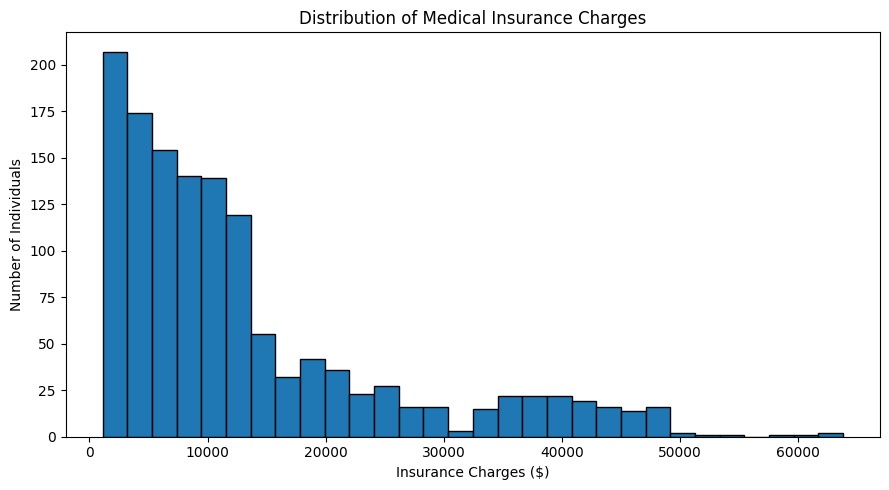

In [14]:
plt.figure(figsize=(9, 5))

plt.hist(df_clean["charges"], bins=30, edgecolor="black")

plt.title("Distribution of Medical Insurance Charges")
plt.xlabel("Insurance Charges ($)")
plt.ylabel("Number of Individuals")

plt.tight_layout()
plt.show()

# Analyzing the age distribution

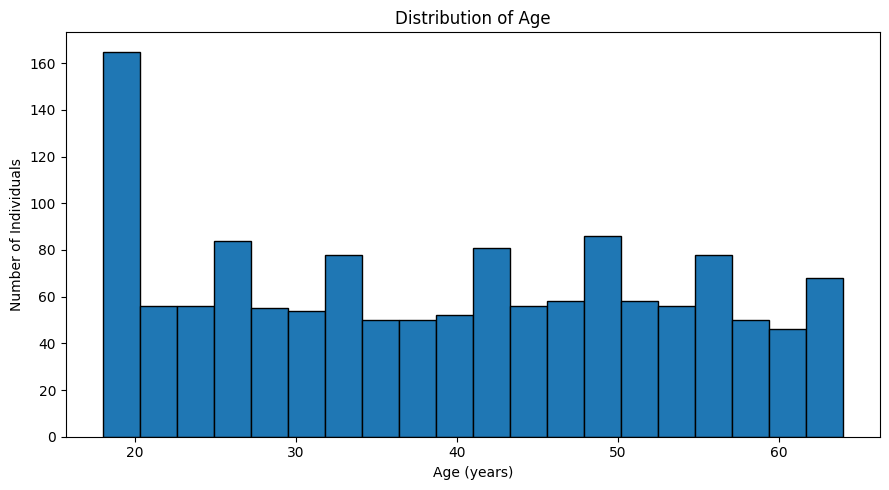

In [15]:
plt.figure(figsize=(9, 5))

plt.hist(df_clean["age"], bins=20, edgecolor="black")

plt.title("Distribution of Age")
plt.xlabel("Age (years)")
plt.ylabel("Number of Individuals")

plt.tight_layout()
plt.show()

In [16]:
print("Mean age:", round(df_clean["age"].mean(), 2))
print("Median age:", df_clean["age"].median())
print("Youngest individual:", df_clean["age"].min())
print("Oldest individual:", df_clean["age"].max())

Mean age: 39.22
Median age: 39.0
Youngest individual: 18
Oldest individual: 64


# Analyzing the BMI distribution

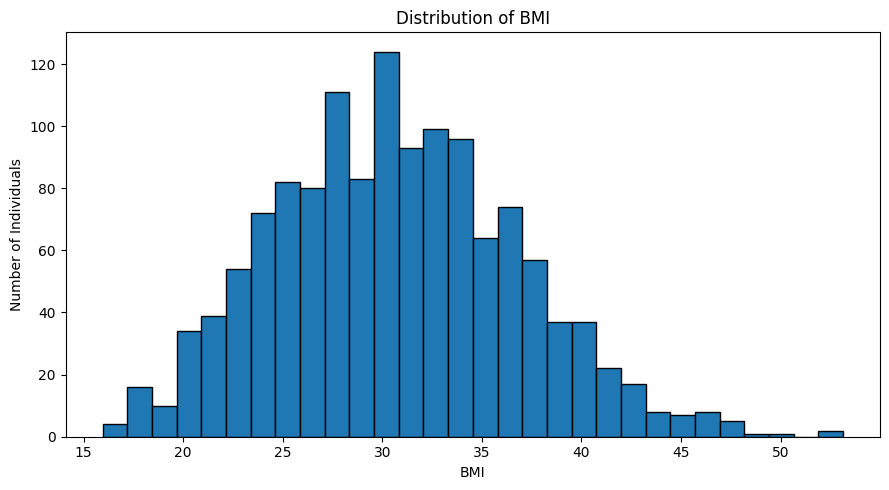

In [17]:
plt.figure(figsize=(9, 5))

plt.hist(df_clean["bmi"], bins=30, edgecolor="black")

plt.title("Distribution of BMI")
plt.xlabel("BMI")
plt.ylabel("Number of Individuals")

plt.tight_layout()
plt.show()

In [18]:
print("Mean BMI:", round(df_clean["bmi"].mean(), 2))
print("Median BMI:", round(df_clean["bmi"].median(), 2))
print("Minimum BMI:", df_clean["bmi"].min())
print("Maximum BMI:", df_clean["bmi"].max())

Mean BMI: 30.66
Median BMI: 30.4
Minimum BMI: 15.96
Maximum BMI: 53.13


# Analyzing the number of children

children
0    573
1    324
2    240
3    157
4     25
5     18
Name: count, dtype: int64


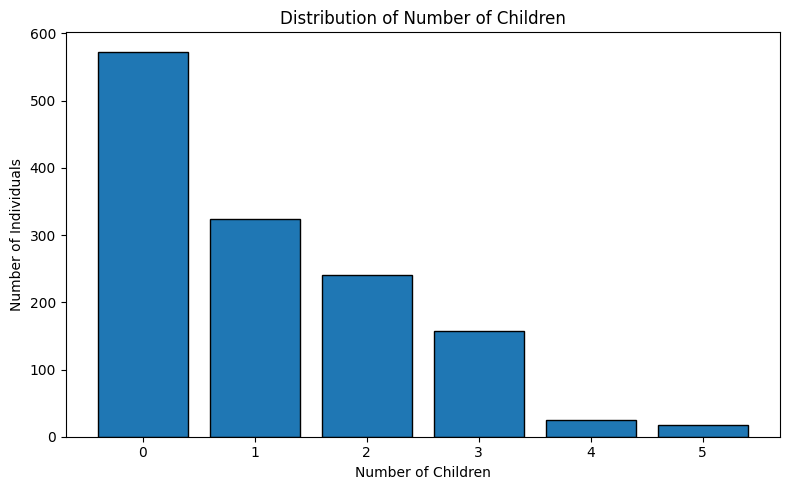

In [19]:
children_counts = df_clean["children"].value_counts().sort_index()

print(children_counts)

plt.figure(figsize=(8, 5))

plt.bar(children_counts.index, children_counts.values, edgecolor="black")

plt.title("Distribution of Number of Children")
plt.xlabel("Number of Children")
plt.ylabel("Number of Individuals")
plt.xticks(children_counts.index)

plt.tight_layout()
plt.show()

In [20]:
print("Mean number of children:", round(df_clean["children"].mean(), 2))
print("Median number of children:", df_clean["children"].median())
print("Maximum number of children:", df_clean["children"].max())

Mean number of children: 1.1
Median number of children: 1.0
Maximum number of children: 5


# Analyzing the categorical variables

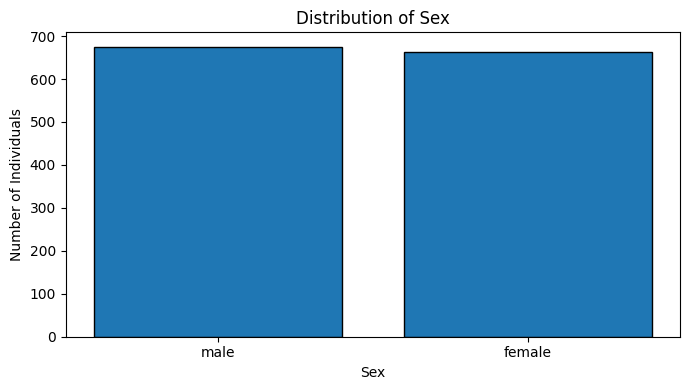

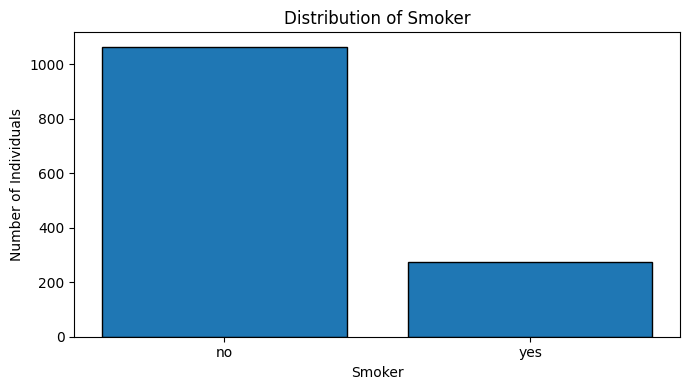

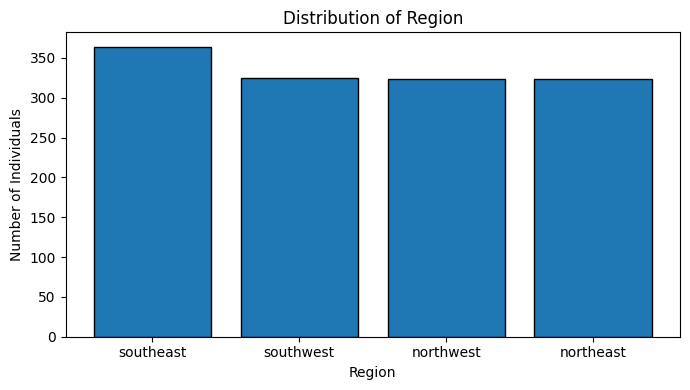

In [21]:
categorical_columns = ["sex", "smoker", "region"]

for col in categorical_columns:
    counts = df_clean[col].value_counts()

    plt.figure(figsize=(7, 4))
    plt.bar(counts.index, counts.values, edgecolor="black")

    plt.title(f"Distribution of {col.capitalize()}")
    plt.xlabel(col.capitalize())
    plt.ylabel("Number of Individuals")

    plt.tight_layout()
    plt.show()

# Bivariate Analysis

# Insurance charges by smoking status

In [22]:
smoker_summary = df_clean.groupby("smoker")["charges"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

display(smoker_summary)

,count,mean,median,min,max
smoker,,,,,
no,1063,8440.66,7345.73,1121.87,36910.61
yes,274,32050.23,34456.35,12829.46,63770.43


<Figure size 800x500 with 0 Axes>

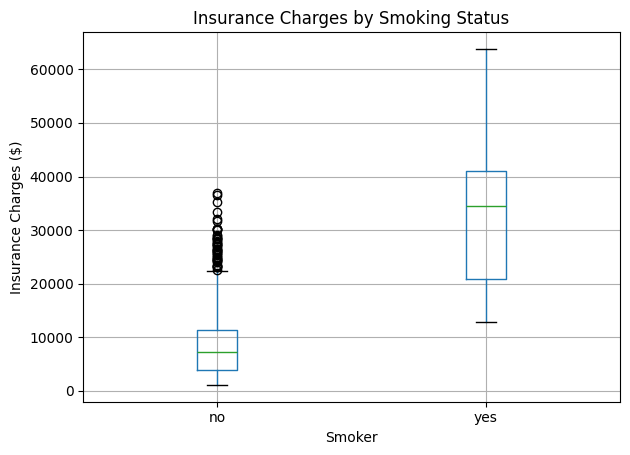

In [23]:
plt.figure(figsize=(8, 5))

df_clean.boxplot(column="charges", by="smoker")

plt.title("Insurance Charges by Smoking Status")
plt.suptitle("")
plt.xlabel("Smoker")
plt.ylabel("Insurance Charges ($)")

plt.tight_layout()
plt.show()

# Insurance charges by age

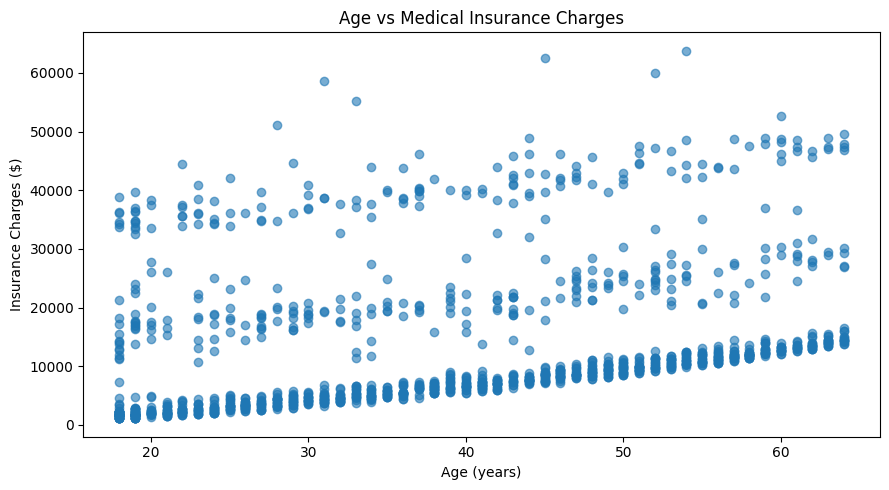

In [24]:
plt.figure(figsize=(9, 5))

plt.scatter(df_clean["age"], df_clean["charges"], alpha=0.6)

plt.title("Age vs Medical Insurance Charges")
plt.xlabel("Age (years)")
plt.ylabel("Insurance Charges ($)")

plt.tight_layout()
plt.show()

In [25]:
age_corr = df_clean["age"].corr(df_clean["charges"])

print("Correlation between age and charges:", round(age_corr, 3))

Correlation between age and charges: 0.298


# BMI vs. insurance charges

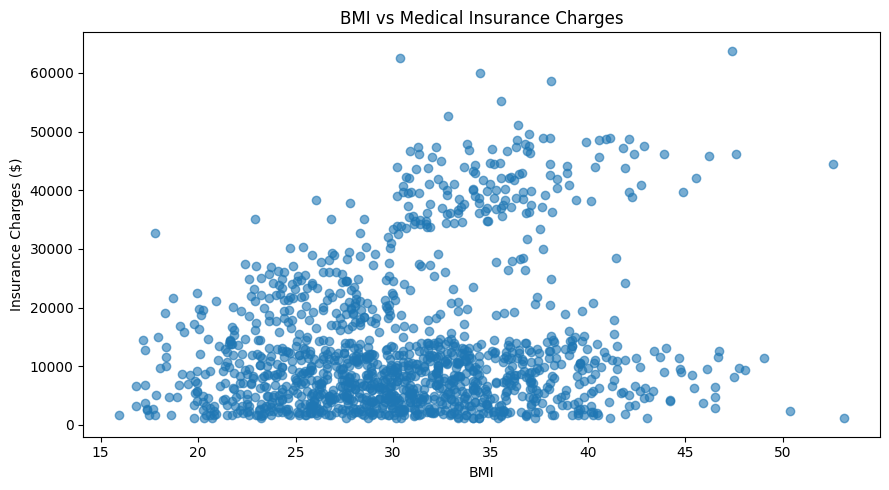

In [26]:
plt.figure(figsize=(9, 5))

plt.scatter(df_clean["bmi"], df_clean["charges"], alpha=0.6)

plt.title("BMI vs Medical Insurance Charges")
plt.xlabel("BMI")
plt.ylabel("Insurance Charges ($)")

plt.tight_layout()
plt.show()

In [27]:
bmi_corr = df_clean["bmi"].corr(df_clean["charges"])

print("Correlation between BMI and charges:", round(bmi_corr, 3))

Correlation between BMI and charges: 0.198


# Charges by sex

In [28]:
sex_summary = df_clean.groupby("sex")["charges"].agg(
    ["count", "mean", "median"]
).round(2)

display(sex_summary)

,count,mean,median
sex,,,
female,662,12569.58,9412.96
male,675,13975.00,9377.90


<Figure size 800x500 with 0 Axes>

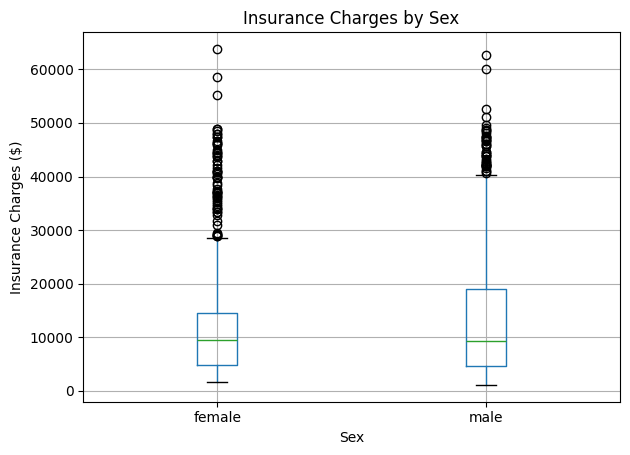

In [29]:
plt.figure(figsize=(8, 5))

df_clean.boxplot(column="charges", by="sex")

plt.title("Insurance Charges by Sex")
plt.suptitle("")
plt.xlabel("Sex")
plt.ylabel("Insurance Charges ($)")

plt.tight_layout()
plt.show()

# Insurance charges by region

In [30]:
region_summary = df_clean.groupby("region")["charges"].agg(
    ["count", "mean", "median"]
).round(2)

display(region_summary)

,count,mean,median
region,,,
northeast,324,13406.38,10057.65
northwest,324,12450.84,8976.98
southeast,364,14735.41,9294.13
southwest,325,12346.94,8798.59


<Figure size 900x500 with 0 Axes>

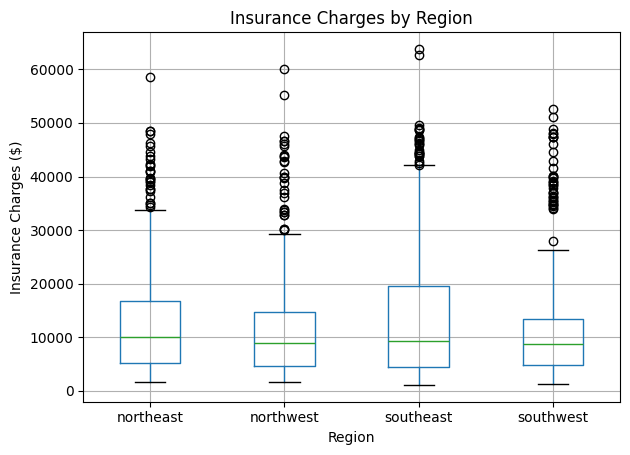

In [31]:
plt.figure(figsize=(9, 5))

df_clean.boxplot(column="charges", by="region")

plt.title("Insurance Charges by Region")
plt.suptitle("")
plt.xlabel("Region")
plt.ylabel("Insurance Charges ($)")

plt.tight_layout()
plt.show()

# Insurance charges by number of children

In [32]:
children_summary = df_clean.groupby("children")["charges"].agg(
    ["count", "mean", "median"]
).round(2)

display(children_summary)

,count,mean,median
children,,,
0,573,12384.70,9863.47
1,324,12731.17,8483.87
2,240,15073.56,9264.98
3,157,15355.32,10600.55
4,25,13850.66,11033.66
5,18,8786.04,8589.57


<Figure size 900x500 with 0 Axes>

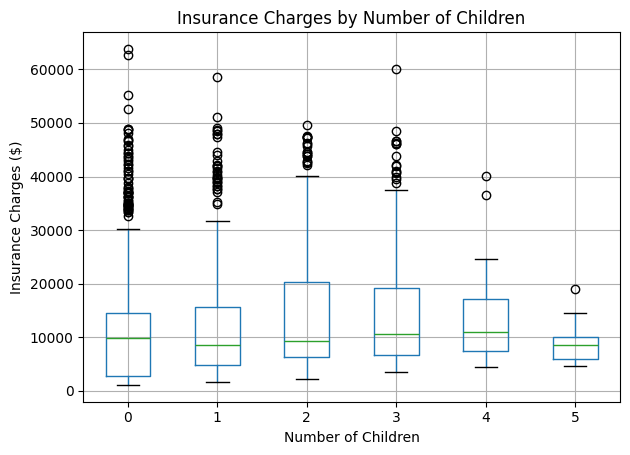

In [33]:
plt.figure(figsize=(9, 5))

df_clean.boxplot(column="charges", by="children")

plt.title("Insurance Charges by Number of Children")
plt.suptitle("")
plt.xlabel("Number of Children")
plt.ylabel("Insurance Charges ($)")

plt.tight_layout()
plt.show()

# Age vs smoking

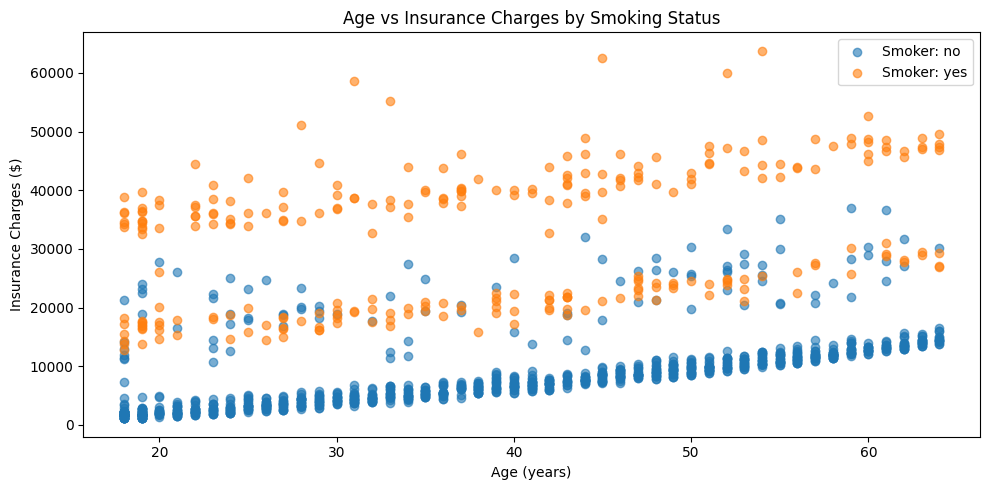

In [34]:
plt.figure(figsize=(10, 5))

for status in ["no", "yes"]:
    subset = df_clean[df_clean["smoker"] == status]

    plt.scatter(
        subset["age"],
        subset["charges"],
        alpha=0.6,
        label=f"Smoker: {status}"
    )

plt.title("Age vs Insurance Charges by Smoking Status")
plt.xlabel("Age (years)")
plt.ylabel("Insurance Charges ($)")
plt.legend()

plt.tight_layout()
plt.show()

In [35]:
age_smoker_corr = df_clean.groupby("smoker").apply(
    lambda group: group["age"].corr(group["charges"]),
    include_groups=False
)

print(age_smoker_corr.round(3))

smoker
no     0.627
yes    0.368
dtype: float64


# BMI vs smoking status

In [36]:
bmi_smoker_corr = df_clean.groupby("smoker").apply(
    lambda group: group["bmi"].corr(group["charges"]),
    include_groups=False
)

print(bmi_smoker_corr.round(3))

smoker
no     0.084
yes    0.806
dtype: float64


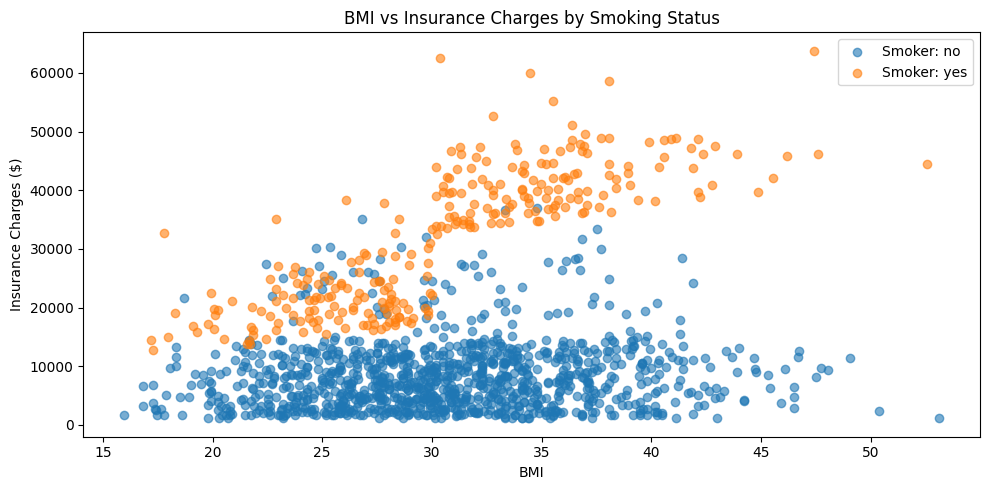

In [37]:
plt.figure(figsize=(10, 5))

for status in ["no", "yes"]:
    subset = df_clean[df_clean["smoker"] == status]

    plt.scatter(
        subset["bmi"],
        subset["charges"],
        alpha=0.6,
        label=f"Smoker: {status}"
    )

plt.title("BMI vs Insurance Charges by Smoking Status")
plt.xlabel("BMI")
plt.ylabel("Insurance Charges ($)")
plt.legend()

plt.tight_layout()
plt.show()

# Age groups vs smoking status

In [39]:
df_clean["age_group"] = pd.cut(
    df_clean["age"],
    bins=[17, 29, 39, 49, 64],
    labels=["18-29", "30-39", "40-49", "50-64"]
)

print(df_clean["age_group"].value_counts().sort_index())

age_group
18-29    416
30-39    257
40-49    279
50-64    385
Name: count, dtype: int64


In [40]:
age_smoker_summary = df_clean.pivot_table(
    index="age_group",
    columns="smoker",
    values="charges",
    aggfunc="mean",
    observed=False
).round(2)

display(age_smoker_summary)

smoker,no,yes
age_group,,
18-29,4426.99,27518.04
30-39,6337.36,30271.25
40-49,9183.34,32654.72
50-64,13430.90,38748.35


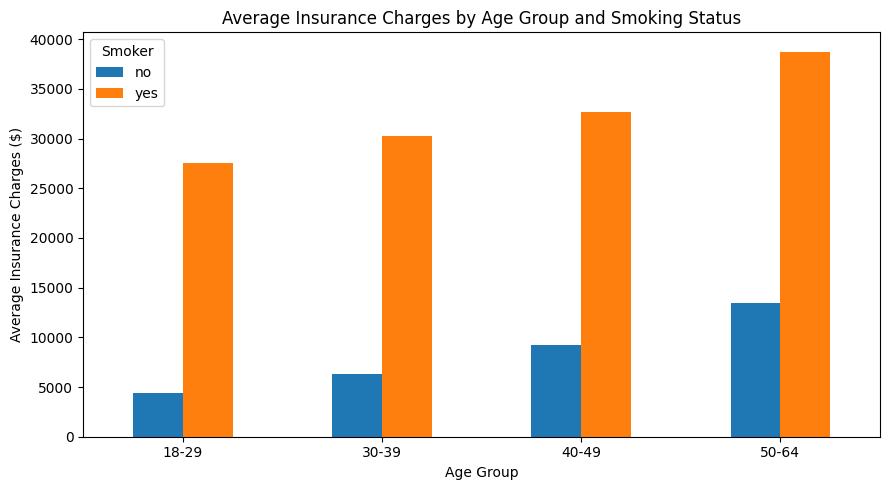

In [41]:
age_smoker_summary.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Average Insurance Charges by Age Group and Smoking Status")
plt.xlabel("Age Group")
plt.ylabel("Average Insurance Charges ($)")
plt.xticks(rotation=0)
plt.legend(title="Smoker")

plt.tight_layout()
plt.show()

# BMI vs smoking status

In [42]:
df_clean["bmi_group"] = pd.cut(
    df_clean["bmi"],
    bins=[0, 25, 30, float("inf")],
    labels=["Below 25", "25 to 30", "Above 30"],
    right=False
)

print(df_clean["bmi_group"].value_counts().sort_index())

bmi_group
Below 25    245
25 to 30    386
Above 30    706
Name: count, dtype: int64


In [43]:
bmi_smoker_summary = df_clean.pivot_table(
    index="bmi_group",
    columns="smoker",
    values="charges",
    aggfunc="mean",
    observed=False
).round(2)

display(bmi_smoker_summary)

smoker,no,yes
bmi_group,,
Below 25,7515.71,19839.28
25 to 30,8257.96,22495.87
Above 30,8855.53,41557.99


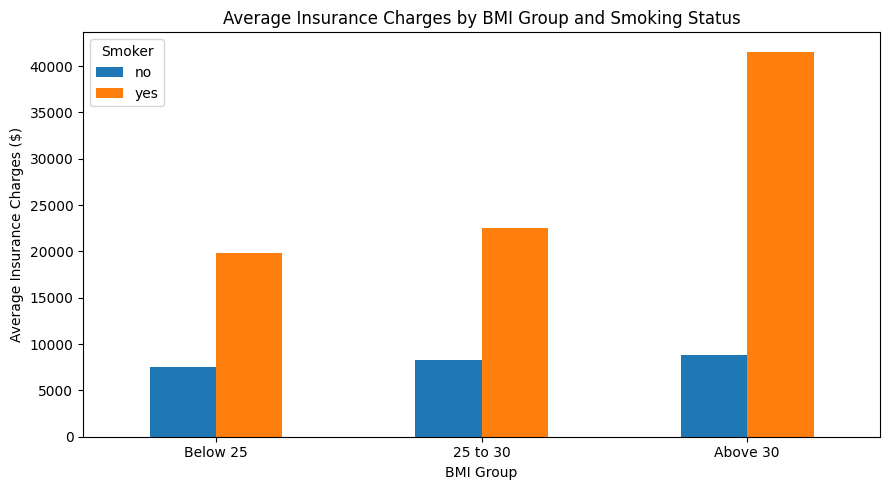

In [44]:
bmi_smoker_summary.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Average Insurance Charges by BMI Group and Smoking Status")
plt.xlabel("BMI Group")
plt.ylabel("Average Insurance Charges ($)")
plt.xticks(rotation=0)
plt.legend(title="Smoker")

plt.tight_layout()
plt.show()

# Checking outliers

In [45]:
numerical_columns = ["age", "bmi", "charges"]

for col in numerical_columns:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    ]

    print(f"\n{col.upper()}")
    print("Lower bound:", round(lower_bound, 2))
    print("Upper bound:", round(upper_bound, 2))
    print("Number of outliers:", len(outliers))
    print("Percentage of dataset:", round(len(outliers) / len(df_clean) * 100, 2), "%")


AGE
Lower bound: -9.0
Upper bound: 87.0
Number of outliers: 0
Percentage of dataset: 0.0 %

BMI
Lower bound: 13.67
Upper bound: 47.32
Number of outliers: 9
Percentage of dataset: 0.67 %

CHARGES
Lower bound: -13120.72
Upper bound: 34524.78
Number of outliers: 139
Percentage of dataset: 10.4 %


# Correlation Overview

In [46]:
correlation_matrix = df_clean[
    ["age", "bmi", "children", "charges"]
].corr()

display(correlation_matrix.round(3))

,age,bmi,children,charges
age,1.000,0.109,0.042,0.298
bmi,0.109,1.000,0.013,0.198
children,0.042,0.013,1.000,0.067
charges,0.298,0.198,0.067,1.000


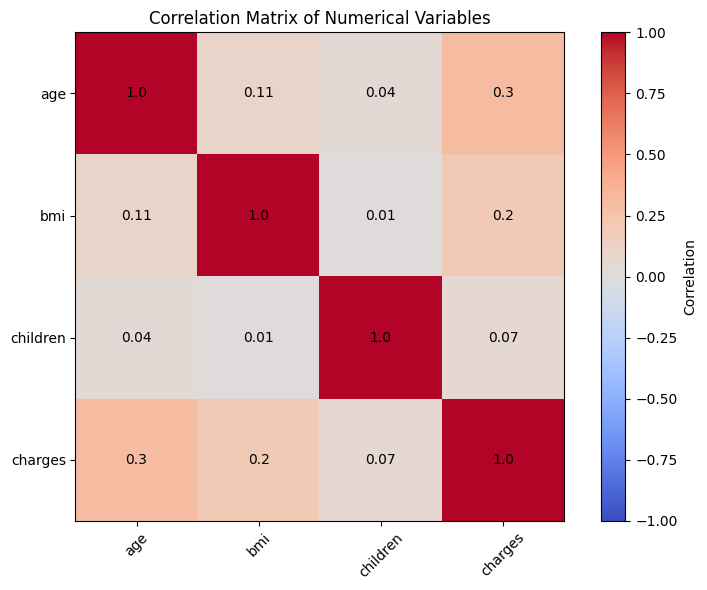

In [47]:
plt.figure(figsize=(8, 6))

plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        plt.text(
            j, i,
            round(correlation_matrix.iloc[i, j], 2),
            ha="center",
            va="center"
        )

plt.title("Correlation Matrix of Numerical Variables")
plt.tight_layout()
plt.show()

# Smoking proportions across regions

In [48]:
region_smoker = pd.crosstab(
    df_clean["region"],
    df_clean["smoker"]
)

display(region_smoker)

smoker,no,yes
region,,
northeast,257,67
northwest,266,58
southeast,273,91
southwest,267,58


In [49]:
region_smoker_pct = pd.crosstab(
    df_clean["region"],
    df_clean["smoker"],
    normalize="index"
) * 100

display(region_smoker_pct.round(2))

smoker,no,yes
region,,
northeast,79.32,20.68
northwest,82.10,17.90
southeast,75.00,25.00
southwest,82.15,17.85


# Final validation of the cleaned dataset

In [50]:
print("Final dataset shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nDuplicate rows:", df_clean.duplicated().sum())

print("\nOriginal columns:")
print(df.columns.tolist())

print("\nWorking dataset columns:")
print(df_clean.columns.tolist())

Final dataset shape: (1337, 9)

Missing values:
age          0
sex          0
bmi          0
children     0
smoker       0
region       0
charges      0
age_group    0
bmi_group    0
dtype: int64

Duplicate rows: 0

Original columns:
['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']

Working dataset columns:
['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges', 'age_group', 'bmi_group']


# Region vs Smoker

In [51]:
region_smoker_charges = df_clean.pivot_table(
    index="region",
    columns="smoker",
    values="charges",
    aggfunc="mean"
).round(2)

display(region_smoker_charges)

smoker,no,yes
region,,
northeast,9165.53,29673.54
northwest,8582.47,30192.00
southeast,8032.22,34845.00
southwest,8019.28,32269.06


# Regional differences within each smoking group

In [52]:
print("Regional charge differences within each smoking group:\n")

print(
    "Non-smokers:",
    round(
        region_smoker_charges["no"].max()
        - region_smoker_charges["no"].min(),
        2
    )
)

print(
    "Smokers:",
    round(
        region_smoker_charges["yes"].max()
        - region_smoker_charges["yes"].min(),
        2
    )
)

Regional charge differences within each smoking group:

Non-smokers: 1146.25
Smokers: 5171.46
